> **Daffa was here**

In [1]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd
import torch

RANDOM_SEED = int(os.environ.get('SKIN_RANDOM_SEED', '42'))
CLASS_NAMES = ('AK', 'BCC', 'MEL', 'NV', 'SCC')
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def findProjectRoot(startPath: Path) -> Path:
    for candidateRoot in (startPath, *startPath.parents):
        if (candidateRoot / 'data' / 'processed').exists() and (candidateRoot / 'notebooks').exists():
            return candidateRoot
    raise RuntimeError('Run from the skin-domain-shift project or one of its subdirectories.')

projectRoot = findProjectRoot(Path.cwd().resolve())
processedRoot = projectRoot / 'data' / 'processed'
artifactRoot = projectRoot / 'artifacts' / 'ds'
figureRoot = projectRoot / 'reports' / 'figures' / 'ds'
reportRoot = projectRoot / 'reports'
artifactRoot.mkdir(parents=True, exist_ok=True)
figureRoot.mkdir(parents=True, exist_ok=True)

def fromProjectPath(pathValue: str) -> Path:
    return (projectRoot / Path(pathValue)).resolve()

runMode = os.environ.get('SKIN_RUN_MODE', 'full').strip().lower()
if runMode not in {'smoke', 'full'}:
    raise ValueError('SKIN_RUN_MODE must be smoke or full.')
runModeRoot = artifactRoot / runMode
runFigureModeRoot = figureRoot / runMode
runArtifactRoot = runModeRoot / f'seed{RANDOM_SEED}'
runFigureRoot = runFigureModeRoot / f'seed{RANDOM_SEED}'
runArtifactRoot.mkdir(parents=True, exist_ok=True)
runFigureRoot.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root: {projectRoot}')
print(f'Run mode: {runMode}; seed: {RANDOM_SEED}')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Avail')

Project root: D:\sunib\Research\Skin\skin-domain-shift
Run mode: full; seed: 42
Device: cuda
GPU Avail


In [2]:
from contextlib import nullcontext
from PIL import Image
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, recall_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

class EvaluationDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, transform, classNames: tuple[str, ...]):
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
        self.classToIndex = {className: index for index, className in enumerate(classNames)}

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int, str]:
        row = self.frame.iloc[index]
        with Image.open(fromProjectPath(row['imagePath'])) as image:
            rgbImage = image.convert('RGB')
        return self.transform(rgbImage), self.classToIndex[row['harmonizedLabel']], row['imageId']

def loadCheckpointModel(checkpointPath: Path) -> tuple[nn.Module, dict]:
    checkpoint = torch.load(checkpointPath, map_location=device, weights_only=False)
    if tuple(checkpoint['classNames']) != CLASS_NAMES:
        raise ValueError('Checkpoint class order does not match evaluation class order.')
    model = models.mobilenet_v3_small(weights=None)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, len(CLASS_NAMES))
    model.load_state_dict(checkpoint['stateDict'])
    model = model.to(device)
    model.eval()
    return model, checkpoint

@torch.inference_mode()
def predictFrame(model: nn.Module, frame: pd.DataFrame, imageSize: int, batchSize: int) -> pd.DataFrame:
    evaluationTransform = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(imageSize),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    dataset = EvaluationDataset(frame, evaluationTransform, CLASS_NAMES)
    dataLoader = DataLoader(dataset, batch_size=batchSize, shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')
    predictionRows = []
    for images, labels, imageIds in tqdm(dataLoader, desc='Evaluating'):
        images = images.to(device, non_blocking=True)
        ampContext = torch.amp.autocast('cuda', enabled=device.type == 'cuda') if device.type == 'cuda' else nullcontext()
        with ampContext:
            probabilities = torch.softmax(model(images), dim=1).cpu().numpy()
        predictedIndices = probabilities.argmax(axis=1)
        for rowIndex, imageId in enumerate(imageIds):
            row = {
                'imageId': imageId,
                'trueLabel': CLASS_NAMES[int(labels[rowIndex])],
                'predictedLabel': CLASS_NAMES[int(predictedIndices[rowIndex])],
            }
            row.update({f'probability{className}': float(probabilities[rowIndex, classIndex]) for classIndex, className in enumerate(CLASS_NAMES)})
            predictionRows.append(row)
    return pd.DataFrame(predictionRows)

def calculateMetrics(predictions: pd.DataFrame) -> dict:
    trueLabels = predictions['trueLabel']
    predictedLabels = predictions['predictedLabel']
    perClassRecallValues = recall_score(
        trueLabels, predictedLabels, labels=list(CLASS_NAMES), average=None, zero_division=0,
    )
    return {
        'sampleCount': len(predictions),
        'macroF1': float(f1_score(trueLabels, predictedLabels, labels=list(CLASS_NAMES), average='macro', zero_division=0)),
        'balancedAccuracy': float(balanced_accuracy_score(trueLabels, predictedLabels)),
        'perClassRecall': {className: float(value) for className, value in zip(CLASS_NAMES, perClassRecallValues)},
        'confusionMatrix': confusion_matrix(trueLabels, predictedLabels, labels=list(CLASS_NAMES)).tolist(),
    }

def stratifiedBootstrapIntervals(predictions: pd.DataFrame, bootstrapCount: int = 1000) -> dict:
    randomGenerator = np.random.default_rng(RANDOM_SEED)
    classIndices = {
        className: predictions.index[predictions['trueLabel'].eq(className)].to_numpy()
        for className in CLASS_NAMES
    }
    bootstrapRows = []
    for _ in range(bootstrapCount):
        sampledIndices = np.concatenate([
            randomGenerator.choice(indices, size=len(indices), replace=True)
            for indices in classIndices.values()
        ])
        sampled = predictions.loc[sampledIndices]
        bootstrapRows.append({
            'macroF1': f1_score(sampled['trueLabel'], sampled['predictedLabel'], labels=list(CLASS_NAMES), average='macro', zero_division=0),
            'balancedAccuracy': balanced_accuracy_score(sampled['trueLabel'], sampled['predictedLabel']),
        })
    bootstrapFrame = pd.DataFrame(bootstrapRows)
    return {
        metricName: {
            'lower95': float(bootstrapFrame[metricName].quantile(0.025)),
            'upper95': float(bootstrapFrame[metricName].quantile(0.975)),
        }
        for metricName in ['macroF1', 'balancedAccuracy']
    }

def plotConfusionMatrix(metrics: dict, title: str, outputPath: Path) -> None:
    import matplotlib.pyplot as plt
    import seaborn as sns

    matrix = np.asarray(metrics['confusionMatrix'])
    rowTotals = matrix.sum(axis=1, keepdims=True)
    normalizedMatrix = np.divide(matrix, rowTotals, out=np.zeros_like(matrix, dtype=float), where=rowTotals != 0)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
    axes[0].set(title=f'{title}: counts', xlabel='Predicted', ylabel='True')
    sns.heatmap(normalizedMatrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
    axes[1].set(title=f'{title}: row-normalized', xlabel='Predicted', ylabel='True')
    figure.tight_layout()
    figure.savefig(outputPath, dpi=300, bbox_inches='tight')
    plt.show()

In [3]:
checkpointPath = runArtifactRoot / 'bestModel.pt'
if not checkpointPath.exists():
    raise FileNotFoundError(f'Missing {checkpointPath}. Run 01_trainClinical.ipynb in {runMode} mode first.')
model, checkpoint = loadCheckpointModel(checkpointPath)
if checkpoint['randomSeed'] != RANDOM_SEED:
    raise ValueError('Checkpoint seed does not match SKIN_RANDOM_SEED.')
clinicalTest = pd.read_csv(processedRoot / 'clinicalTest.csv', low_memory=False)
if runMode == 'smoke':
    clinicalTest = clinicalTest.groupby('harmonizedLabel', group_keys=False).head(3).reset_index(drop=True)
assert set(clinicalTest['harmonizedLabel']) == set(CLASS_NAMES)
print(f'Clinical test images: {len(clinicalTest):,}')

Clinical test images: 294


## 3. Predictions and concise metrics

In [4]:
batchSize = int(os.environ.get('SKIN_EVAL_BATCH_SIZE', '64' if device.type == 'cuda' else '16'))
clinicalPredictions = predictFrame(model, clinicalTest, int(checkpoint['imageSize']), batchSize)
clinicalMetrics = calculateMetrics(clinicalPredictions)
clinicalMetrics['confidenceIntervals'] = stratifiedBootstrapIntervals(
    clinicalPredictions, bootstrapCount=1000 if runMode == 'full' else 100,
)
clinicalMetrics['dataset'] = 'clinicalTest'
clinicalMetrics['runMode'] = runMode
clinicalMetrics['randomSeed'] = RANDOM_SEED
clinicalMetrics['paperResultsEligible'] = runMode == 'full'

clinicalPredictionsPath = runArtifactRoot / 'clinicalTestPredictions.csv'
clinicalMetricsPath = runArtifactRoot / 'clinicalTestMetrics.json'
clinicalPredictions.to_csv(clinicalPredictionsPath, index=False)
clinicalMetricsPath.write_text(json.dumps(clinicalMetrics, indent=2), encoding='utf-8')
print(json.dumps(clinicalMetrics, indent=2))
if runMode == 'smoke':
    print('SMOKE ONLY: these metrics are not valid paper results.')

Evaluating:   0%|          | 0/5 [00:00<?, ?it/s]

{
  "sampleCount": 294,
  "macroF1": 0.5550384346983812,
  "balancedAccuracy": 0.6071797414842234,
  "perClassRecall": {
    "AK": 0.6019417475728155,
    "BCC": 0.6048387096774194,
    "MEL": 0.7142857142857143,
    "NV": 0.8421052631578947,
    "SCC": 0.2727272727272727
  },
  "confusionMatrix": [
    [
      62,
      19,
      2,
      4,
      16
    ],
    [
      11,
      75,
      0,
      12,
      26
    ],
    [
      0,
      0,
      5,
      2,
      0
    ],
    [
      1,
      1,
      4,
      32,
      0
    ],
    [
      2,
      11,
      0,
      3,
      6
    ]
  ],
  "confidenceIntervals": {
    "macroF1": {
      "lower95": 0.4804411986321161,
      "upper95": 0.6250037032067461
    },
    "balancedAccuracy": {
      "lower95": 0.519528641451021,
      "upper95": 0.685885428897672
    }
  },
  "dataset": "clinicalTest",
  "runMode": "full",
  "randomSeed": 2026,
  "paperResultsEligible": true
}


## 4. Confusion matrices

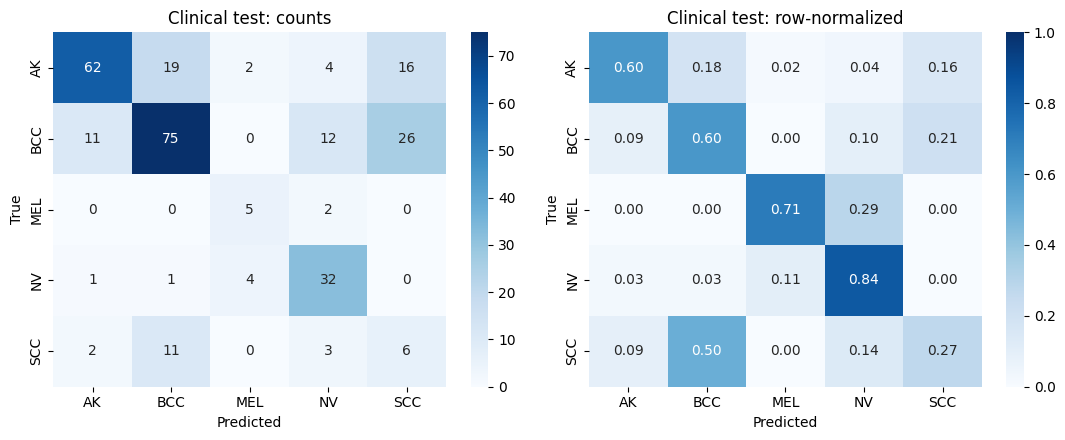

In [5]:
clinicalFigurePath = runFigureRoot / 'clinicalTestConfusionMatrix.png'
plotConfusionMatrix(clinicalMetrics, 'Clinical test', clinicalFigurePath)
assert clinicalFigurePath.exists() and clinicalFigurePath.stat().st_size > 0